In [1]:
import os

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import matplotlib.tri as tri

In [3]:
# model_folder = "run_fibernet_20261119_155937_290753" # Corrected gradients in physics loss, No normalization layer, Data + physics (50000 with data and physics), original g_il values used for training
model_folder = "run_fibernet_20261118_183827_433102" # Corrected gradients in physics loss, Data + physics (50000 with data and physics), original g_il values used for training
# model_folder = "run_fibernet_20261118_141045_963088" # Data + physics (50000 with data and physics), original g_il values used for training
# model_folder = "run_fibernet_20261118_131054_247268" # Data + physics (16667 optimizer updates with data only, 33333 with data and physics), original g_il values used for training
# model_folder = "run_fibernet_20261116_164838_933228" # Data only, original g_il values used for training
# model_folder = "run_fibernet_20261117_175535_936586" # Data only, new g_il values used for training

train_loss_path = os.path.abspath("./experiments/case_1/" + model_folder + "/losses.npy")
phys_losses_path = os.path.abspath("./experiments/case_1/" + model_folder + "/losses_phys.npy")

In [4]:
train_losses = np.load(train_loss_path)
phys_losses = np.load(phys_losses_path)

In [5]:
iterations_phys = phys_losses[:, 0]
pde_loss = phys_losses[:, 1]
ode_loss = phys_losses[:, 2]
bc_loss = phys_losses[:, 3]
ic_v_loss = phys_losses[:, 4]
ic_w_loss = phys_losses[:, 5]

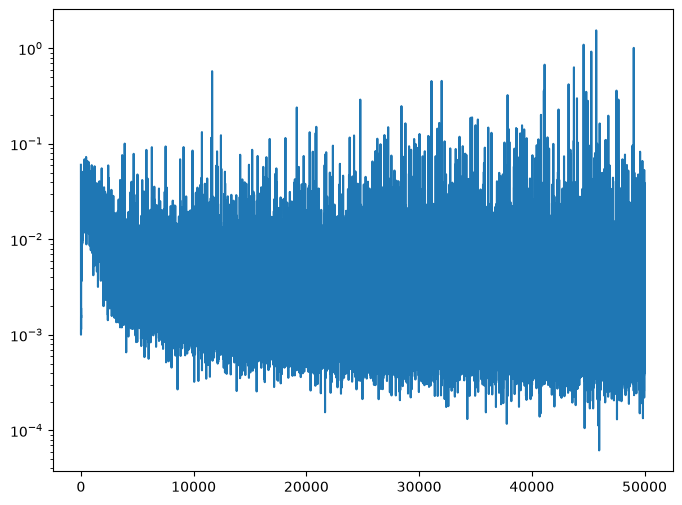

In [6]:
fig = plt.figure(figsize=(8, 6))
plt.plot(iterations_phys, pde_loss, label="PDE loss")
# plt.plot(iterations_phys, ode_loss, label="ODE loss")
# plt.plot(iterations_phys, bc_loss, label="BC loss")
# plt.plot(iterations_phys, ic_v_loss, label="IC v loss")
# plt.plot(iterations_phys, ic_w_loss, label="IC w loss")

plt.yscale("log")

In [7]:
iterations = train_losses[:, 0]
mse_v = train_losses[:, 1]
mse_w = train_losses[:, 2]
rel_v = train_losses[:, 3]
rel_w = train_losses[:, 4]
mae_v = train_losses[:, 5]
mae_w = train_losses[:, 6]

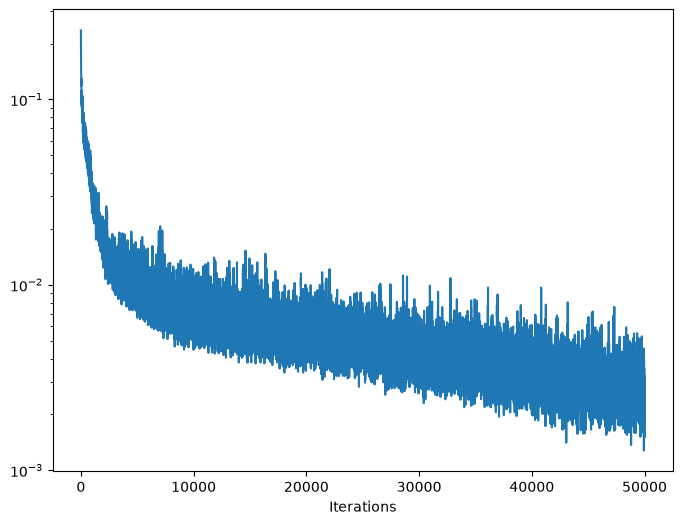

In [8]:
fig = plt.figure(figsize=(8, 6))
# plt.plot(iterations, rel_v, label="REL v")
plt.plot(iterations, mse_v, label="MSE v")

plt.xlabel("Iterations")
# plt.ylabel("Relative L1 Error (V)")
plt.yscale("log")

In [9]:
losses = {
    'pde_loss': pde_loss,
    'ode_loss': ode_loss,
    'bc_loss': bc_loss,
    'ic_loss': ic_v_loss,
    'data_loss': mse_v
}

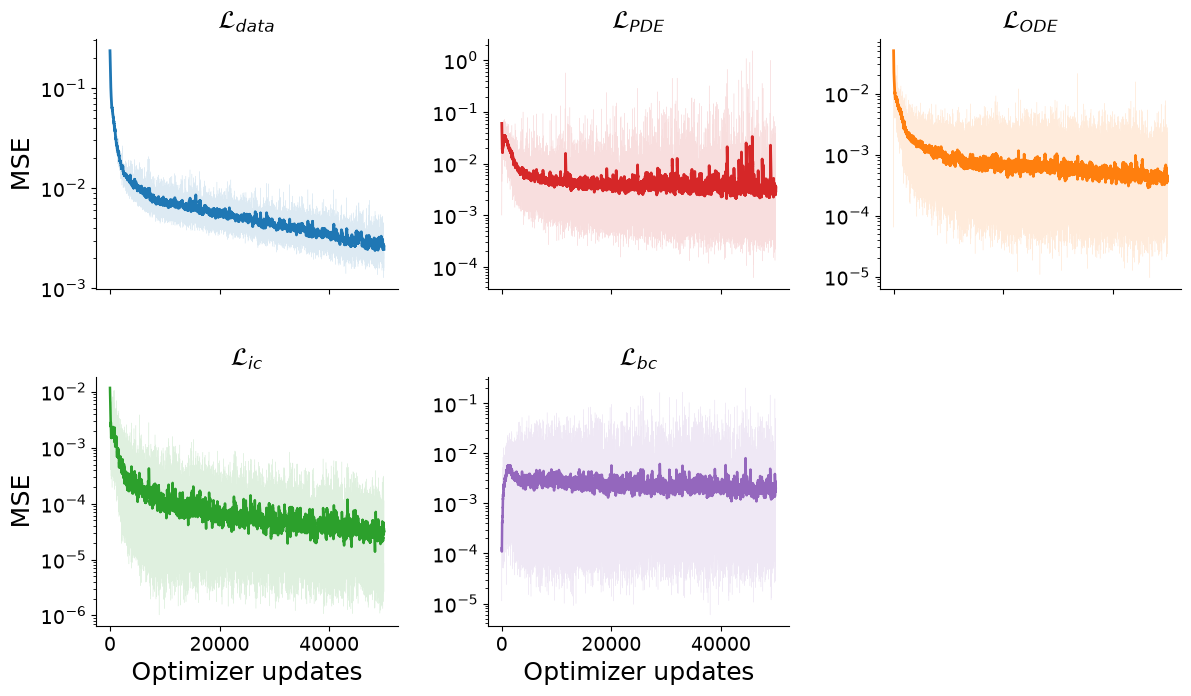

In [10]:
import math
import pandas as pd

losses_df = pd.DataFrame(losses)

loss_styles = {
    # 'total_loss':   {'label': r'$\mathcal{L}(\theta)$', 'color': '#8c564b', 'lw': 2.5, 'ls': '-',  'alpha': 1.0},
    'data_loss':    {'label': r'$\mathcal{L}_{data}$',  'color': '#1f77b4', 'lw': 2.0, 'ls': '-',  'alpha': 1.0},
    'pde_loss':     {'label': r'$\mathcal{L}_{PDE}$',   'color': '#d62728', 'lw': 2.0, 'ls': '-',  'alpha': 1.0},
    'ode_loss':     {'label': r'$\mathcal{L}_{ODE}$',   'color': '#ff7f0e', 'lw': 2.0, 'ls': '-',  'alpha': 1.0},
    'ic_loss': {'label': r'$\mathcal{L}_{ic}$',    'color': '#2ca02c', 'lw': 1.8, 'ls': '-',  'alpha': 1.0},
    # 'initial_loss_at_stim': {'label': r'$\mathcal{L}_{ic}$ at stimulation site',    'color': '#2ca02c', 'lw': 1.8, 'ls': '-',  'alpha': 1.0},
    'bc_loss':      {'label': r'$\mathcal{L}_{bc}$',    'color': '#9467bd', 'lw': 1.8, 'ls': '-',  'alpha': 1.0},
    # 'surface_loss': {'label': r'$\mathcal{L}_{surf}$',  'color': '#e377c2', 'lw': 1.8, 'ls': '-',  'alpha': 1.0},
}

def ema(series, alpha=0.02):
    return series.ewm(alpha=alpha, adjust=False).mean()

# Determine which losses are present
available_losses = [key for key in losses.keys() if not pd.isnull(losses[key]).all()]
component_losses = ['data_loss', 'pde_loss', 'ode_loss', 'initial_loss', 'initial_loss_at_stim', 'bc_loss', 'surface_loss']


# Create grid: 1 row for total, 2 rows for components (3 per row)
# n_component_rows = 2
# n_cols = 3
# fig = plt.figure(figsize=(14, 8))
# gs = fig.add_gridspec(3, n_cols, height_ratios=[1, 1, 1], hspace=0.35, wspace=0.3)

n_cols = 3
n_component_rows = math.ceil(len(loss_styles.keys()) / n_cols)
fig = plt.figure(figsize=(14, 4 + 4 * n_component_rows))
gs = fig.add_gridspec(
    1 + n_component_rows,
    n_cols,
    height_ratios=[1] + [1] * n_component_rows,
    hspace=0.35,
    wspace=0.3,
)


# # Plot total loss spanning all columns in first row
# ax_total = fig.add_subplot(gs[0, :])
# if 'total_loss' in df.columns:
#     style = loss_styles['total_loss']
#     series = df['total_loss'].replace(0, float('nan'))
#     smoothed = ema(series)
#     ax_total.plot(series, color=style['color'], linewidth=0.3,
#                     linestyle=style['ls'], alpha=0.15)
#     ax_total.plot(smoothed, label=style['label'], color=style['color'],
#                     linewidth=style['lw'], linestyle=style['ls'], alpha=style['alpha'])
    
#     ax_total.set_yscale('log')
#     ax_total.set_ylabel('MSE', fontsize=18)
#     ax_total.legend(frameon=True, fontsize=18, loc='best')
#     ax_total.spines['top'].set_visible(False)
#     ax_total.spines['right'].set_visible(False)
#     ax_total.tick_params(labelbottom=False, labelsize=14)

# Plot each component loss in its own subplot
for idx, col in enumerate(loss_styles.keys()):
    row = 1 + idx // n_cols
    col_pos = idx % n_cols
    ax = fig.add_subplot(gs[row, col_pos])
    
    style = loss_styles[col]
    series = losses_df[col].replace(0, float('nan'))
    smoothed = ema(series)
    
    ax.plot(series, color=style['color'], linewidth=0.3,
            linestyle=style['ls'], alpha=0.15)
    ax.plot(smoothed, color=style['color'],
            linewidth=style['lw'], linestyle=style['ls'], alpha=style['alpha'])
    
    ax.set_yscale('log')
    ax.set_title(style['label'], fontsize=18, pad=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=14)
    
    # Only show x-label on bottom row
    if row == 2:
        ax.set_xlabel('Optimizer updates', fontsize=18)
    else:
        ax.tick_params(labelbottom=False)

    if col_pos == 0:
        ax.set_ylabel('MSE', fontsize=18)

In [11]:
rel_v.min()

np.float64(0.04245925694704056)

### Run PINN on test data

In [12]:
from case_data import CaseData, load_case_data, load_fields, resolve_case, case_dataset_path, resolve_cases
from scar_data_module import detect_device
from utils import load_config

from scar_data_module import ScarPINNDataModule
from pinn import PINN2D

In [13]:
DATA_SPLIT_UPDATED = {"train": [0.03, 0.035, 0.04, 0.05, 0.055, 0.06, 0.07, 0.075, 0.08, 0.09, 0.095, 0.1],
              "interpolation": [0.045, 0.065, 0.085],
              "extrapolation": [0.01, 0.015, 0.02, 0.025]}

DATA_SPLIT = {"train": [0.01, 0.015, 0.02, 0.03, 0.035, 0.04, 0.05, 0.055, 0.06, 0.07, 0.075, 0.08],
              "interpolation": [0.025, 0.045, 0.065],
              "extrapolation": [0.085, 0.09, 0.095, 0.1]}

INDICES = np.arange(19)

#### Setup data

In [14]:
device = detect_device()
case = "case_1"
# model_folder = "run_fibernet_20261117_175535_936586"

config_path = os.path.abspath("./experiments/case_1/" + model_folder + "/config.yaml")

config = load_config(config_path)
dataset_path = case_dataset_path(case)

In [15]:
# Test on all vertices in the dataset
config['DATA']['sampling']['nx_test_slice'] = 1

In [16]:
dm = ScarPINNDataModule(config, case=case)
dm.setup_data()

Loading data
Using device: cuda
Dataset: data/scar_ep_case_1.h5
Geometry: case_1: 72344 vertices, 138524 collocation points, 10968 boundary points, 19 sims x 241 frames
Fields: vm (12, 241, 72344) (0.78 GiB x2), experiments [0.009999999776482582, 0.014999999664723873, 0.019999999552965164, 0.029999999329447746, 0.03500000014901161, 0.03999999910593033, 0.05000000074505806, 0.054999999701976776, 0.05999999865889549, 0.07000000029802322, 0.07500000298023224, 0.07999999821186066]
Training data: 209217824 samples, 51079 batches of size 4096, 72344 vertices, 241 time steps, 12 experiments
Collocation data: 400611408 samples, batch size 100
Boundary data: 31719456 samples, 317195 batches of size 100


In [17]:
vm_all = load_fields(dataset_path, np.arange(19))[0]

In [37]:
# # DATA_SPLIT = DATA_SPLIT_UPDATED

training_indices = np.where([g_il_value in DATA_SPLIT['train'] for g_il_value in dm.case_data.g_il])[0]
interpolation_indices = np.where([g_il_value in DATA_SPLIT['interpolation'] for g_il_value in dm.case_data.g_il])[0]
extrapolation_indices = np.where([g_il_value in DATA_SPLIT['extrapolation'] for g_il_value in dm.case_data.g_il])[0]

In [19]:
# extrapolation_indices, interpolation_indices, training_indices

In [20]:
# vm_training, _ = load_fields(dataset_path, training_indices)
# vm_interpolation, _ = load_fields(dataset_path, interpolation_indices)
# vm_extrapolation, _ = load_fields(dataset_path, extrapolation_indices)

#### Load trained PINN

In [21]:
# best_model_path = os.path.abspath("./experiments/case_1/" + model_folder + "/model_data_best.pth")
best_model_path = os.path.abspath("./experiments/case_1/" + model_folder + "/model_best.pth")

In [22]:
model = PINN2D(config, dm.mins, dm.maxes)
state = torch.load(best_model_path, map_location=device, weights_only=True)
model.load_state_dict(state)
model.eval()

Initializing PINN
Using CUDA device
PINN2D architecture:
Sequential(
  (0): Linear(in_features=4, out_features=4, bias=True)
  (1): Linear(in_features=4, out_features=256, bias=True)
  (2): Linear(in_features=256, out_features=256, bias=True)
  (3): Tanh()
  (4): Linear(in_features=256, out_features=256, bias=True)
  (5): Tanh()
  (6): Linear(in_features=256, out_features=256, bias=True)
  (7): Tanh()
  (8): Linear(in_features=256, out_features=256, bias=True)
  (9): Tanh()
  (10): Linear(in_features=256, out_features=256, bias=True)
  (11): Tanh()
  (12): Linear(in_features=256, out_features=256, bias=True)
  (13): Tanh()
  (14): Linear(in_features=256, out_features=256, bias=True)
  (15): Tanh()
  (16): Linear(in_features=256, out_features=256, bias=True)
  (17): Tanh()
  (18): Linear(in_features=256, out_features=256, bias=True)
  (19): SiLU()
  (20): Linear(in_features=256, out_features=2, bias=True)
)


PINN2D(
  (layer_norm): Linear(in_features=4, out_features=4, bias=True)
  (model): Sequential(
    (0): Linear(in_features=4, out_features=4, bias=True)
    (1): Linear(in_features=4, out_features=256, bias=True)
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): Tanh()
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): Tanh()
    (6): Linear(in_features=256, out_features=256, bias=True)
    (7): Tanh()
    (8): Linear(in_features=256, out_features=256, bias=True)
    (9): Tanh()
    (10): Linear(in_features=256, out_features=256, bias=True)
    (11): Tanh()
    (12): Linear(in_features=256, out_features=256, bias=True)
    (13): Tanh()
    (14): Linear(in_features=256, out_features=256, bias=True)
    (15): Tanh()
    (16): Linear(in_features=256, out_features=256, bias=True)
    (17): Tanh()
    (18): Linear(in_features=256, out_features=256, bias=True)
    (19): SiLU()
    (20): Linear(in_features=256, out_features=2, bias=True)
  )
)

#### Make predictions

In [23]:
# indices = extrapolation_indices
# indices = interpolation_indices
# indices = training_indices

def make_predictions(dm, model, indices):

    x = dm.dataset.x
    y = dm.dataset.y

    n_vertices = len(x)
    n_timesteps = len(dm.dataset.t)
    total = n_vertices * n_timesteps

    pred = np.empty((len(indices), total), dtype=np.float32)
    with torch.no_grad():
        for i in range(len(indices)):
            for start in range(0, total, 10000):
                end = min(start + 10000, total)
                flat = np.arange(start, end)

                time_idx = flat // n_vertices
                vertex_idx = flat % n_vertices

                X = np.column_stack((
                    x[vertex_idx],
                    y[vertex_idx],
                    dm.dataset.t[time_idx],
                    np.full_like(flat, dm.case_data.g_il[indices[i]])
                )).astype(np.float32)

                X = torch.from_numpy(X).to(device)
                pred[i, flat] = model.predict(X).squeeze(1).cpu().numpy()

        pred = pred.reshape((len(indices), n_timesteps, n_vertices))

    return pred

In [24]:
preds = make_predictions(dm, model, np.arange(19))

In [25]:
def compute_errors(indices, vm, preds):
    errors = np.empty(len(indices), dtype=np.float32)

    for i in range(len(indices)):
        abs_sum = np.sum(np.abs(vm[i] - preds[i]))
        v_sum = np.sum(np.abs(vm[i]))
        errors[i] = abs_sum / v_sum

    return errors

In [26]:
errors = compute_errors(INDICES, vm_all, preds)

In [27]:
errors

array([0.0547314 , 0.0624155 , 0.07451025, 0.0817426 , 0.08634901,
       0.09038071, 0.09381196, 0.09675621, 0.09936278, 0.10175129,
       0.10400205, 0.10615773, 0.10825575, 0.11032461, 0.11239536,
       0.11444243, 0.11644449, 0.11839168, 0.12027526], dtype=float32)

In [39]:
errors[training_indices].mean()

np.float32(0.09152422)

In [28]:
vm_all.shape, preds.shape

((19, 241, 72344), (19, 241, 72344))

In [29]:
preds_reshaped = preds.transpose(1, 2, 0)
vm_all_reshaped = vm_all.transpose(1, 2, 0)

In [30]:
vm_all_reshaped.shape, preds_reshaped.shape

((241, 72344, 19), (241, 72344, 19))

In [31]:
# Save preds and ground truth to .npy files
np.save(os.path.abspath("./data/vm_PINN.npy"), preds_reshaped)
np.save(os.path.abspath("./data/vm_variation_scar_full.npy"), vm_all_reshaped)

In [32]:
class MeshPlotData(object):
    def __init__(self, cmap, vmin, vmax, case_data):
        self.cmap = cmap
        self.vmin = vmin
        self.vmax = vmax

        # self.vertices, self.triangles, _ = get_mesh_data()
        # self.vertices *= 1e-3
        self.vertices = case_data.vertices
        self.triangles = case_data.topology

        self.triang = tri.Triangulation(self.vertices[:,0], 
                                        self.vertices[:,1],
                                        self.triangles)

class VMMeshPlotData(MeshPlotData):
    def __init__(self, t_plot, case_data):
        super().__init__('cividis', -80, 20, case_data)

        self.vm_FEM   = np.load("./data/vm_variation_scar_full.npy")            # (T, V, E)
        self.vm_PIMM = np.load("./data/vm_PINN.npy")            # (T, V, E)
        #cond_all = np.load("./data/conductivities_variation_scar_full.npy")
        #cond_all *= 12.9/1.4

        dt = 5
        T  = self.vm_FEM.shape[0]
        # T  = self.vm_FEM.shape[1]
        t  = np.linspace(0, (T-1)*dt, T)/12.9

        self.frame = int(t_plot/dt)
        if self.frame < 0 or self.frame >= T:
            raise ValueError("t_plot out of range")

        self.t_plot = t_plot

    def _get_data(self, exp_idx):
        # FEM solution at t_plot
        v_fem = self.vm_FEM[self.frame, :, exp_idx]
        # v_fem = self.vm_FEM[exp_idx, self.frame, :]

        # PINN prediction
        v_pinn = self.vm_PIMM[self.frame, :, exp_idx]
        # v_pinn = self.vm_PIMM[exp_idx, self.frame, :]
        return v_fem, v_pinn, self.triang

    def comparative_plot(self, ax_FEM, ax_PINN, exp_idx):
        fem_vm, pinn_vm, triang = self._get_data(exp_idx)
        
        pcm = ax_FEM.tripcolor(triang,
                               fem_vm, 
                               shading='gouraud',
                               cmap=self.cmap,
                               vmin=self.vmin,
                               vmax=self.vmax,
                               rasterized = True)

        ax_PINN.tripcolor(triang,
                          pinn_vm,
                          shading='gouraud',
                          cmap=self.cmap,
                          vmin=self.vmin,
                          vmax=self.vmax,
                          rasterized = True)
        return pcm

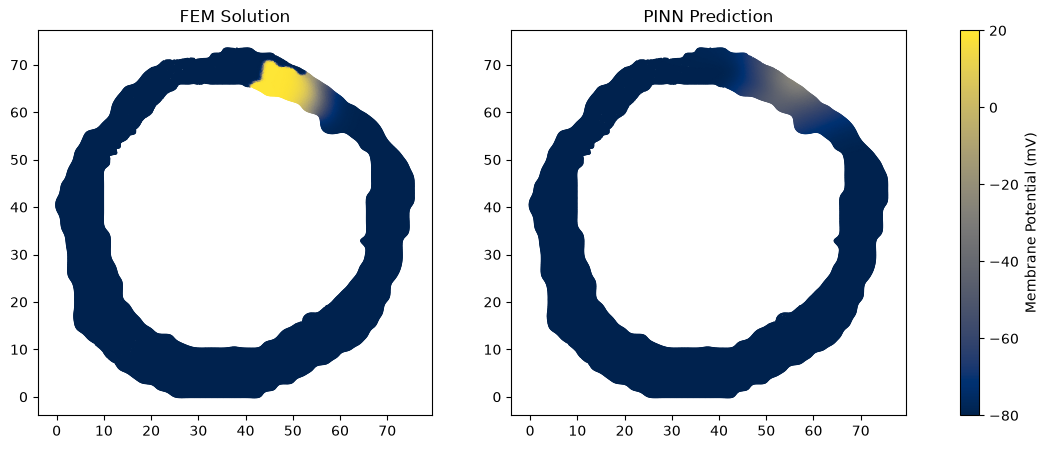

In [47]:
vm_plotter = VMMeshPlotData(t_plot=50, case_data=dm.case_data)

fig, (ax_fem, ax_pinn) = plt.subplots(1, 2, figsize=(14, 5))
pcm = vm_plotter.comparative_plot(ax_fem, ax_pinn, 0)

ax_fem.set_title("FEM Solution")
ax_pinn.set_title("PINN Prediction")
fig.colorbar(pcm, ax=[ax_fem, ax_pinn], orientation='vertical', label='Membrane Potential (mV)')
plt.show()

In [76]:
from utils import get_mesh_data
import matplotlib.tri as tri
import matplotlib.animation as animation

ANIM_OUTDIR = os.path.abspath("./results/animations/ingvild/data_and_physics_from_start/100_mesh_nodes/original_gil_values/")
EXPERIMENT_GILS = np.linspace(0.01, 0.1, 19)
ANIM_CODEC = "libx264"


def _ensure_dir(path):
    os.makedirs(path, exist_ok=True)

def _triangulation_from_utils(case_data):
    # vertices, triangles, _ = get_mesh_data()
    # vertices = vertices * 1e-3
    vertices = case_data.vertices
    triangles = case_data.topology
    triang = tri.Triangulation(vertices[:, 0], vertices[:, 1], triangles)
    return vertices, triang

def _apply_axes_style(ax, zoom):
    if zoom is not None:
        ax.set_ylim(zoom[0], zoom[1])
        ax.set_xlim(zoom[2], zoom[3])
    ax.set_xlabel("x [mm]")
    ax.set_ylabel("y [mm]")
    ax.set_aspect("equal")

def animation_PINN_FEM(exp_idx,
                       *,
                       zoom=None,
                       fps=20,
                       bitrate=1000,
                       filename=None):
    """
    Side-by-side animation of PINN vs FEM for experiment index exp_idx.
    Uses saved arrays: ./data/vm_PINN.npy and ./data/vm_variation_scar_full.npy
    """
    _ensure_dir(ANIM_OUTDIR)
    vertices, triang = _triangulation_from_utils(dm.case_data)

    print(vertices.shape)

    v_FEM_all  = np.load("./data/vm_variation_scar_full.npy")  # (T, V, E)
    v_PINN_all = np.load("./data/vm_PINN.npy")                  # (T, V, E)

    v_FEM  = v_FEM_all[:, :, exp_idx]
    v_PINN = v_PINN_all[:, :, exp_idx]
    g_il = EXPERIMENT_GILS[exp_idx]

    print(v_FEM.shape, v_PINN.shape, g_il)

    T_len, V_count = v_FEM.shape
    assert v_PINN.shape == (T_len, V_count)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(24, 10))

    im1 = ax1.tripcolor(triang, v_PINN[0, :], shading="gouraud", cmap=plt.cm.cividis, vmin=-80, vmax=20)
    im2 = ax2.tripcolor(triang, v_FEM[0,  :], shading="gouraud", cmap=plt.cm.cividis, vmin=-80, vmax=20)


    cbar = fig.colorbar(im2, ax=[ax1, ax2],  # span both axes
                    orientation="vertical",
                    fraction=0.046, pad=0.04)
    cbar.set_label(r"$V_m$ [mV]")
    _apply_axes_style(ax1, zoom)
    _apply_axes_style(ax2, zoom)
    ax1.set_title(r"$\bf{PINN}$: $g_{il}$="+f"{g_il:.3f}S/m", fontsize=20)
    ax2.set_title(r"$\bf{FEM}$: $g_{il}$="+f"{g_il:.3f}S/m",  fontsize=20)

    def update(frame):
        v_pred = v_PINN[frame, :]
        v_true = v_FEM[frame,  :]

        im1.set_array(v_pred)
        im2.set_array(v_true)

        # Per-frame RL1 (consistent with your older title behavior)
        denom = np.sum(np.abs(v_true))
        RL1 = (np.sum(np.abs(v_true - v_pred)) / denom) if denom > 0 else np.nan

        ax1.set_title(r"$\bf{PINN}$: $g_{il}$="+f"{g_il:.3f}S/m" + f"\n t={frame*5:.0f} ms, RL1={RL1:.3f}", fontsize=20)
        ax2.set_title(r"$\bf{FEM}$: $g_{il}$="+f"{g_il:.3f}S/m"  + f"\n t={frame*5:.0f} ms",               fontsize=20)
        return im1, im2

    ani = animation.FuncAnimation(fig, update, frames=T_len, interval=1, blit=False)

    if filename is None:
        filename = f"S{exp_idx+1}_vm_pinn_fem_gil_{g_il:.3f}.mp4"
    outpath = os.path.join(ANIM_OUTDIR, filename)
    ani.save(outpath, writer=animation.FFMpegWriter(fps=fps, codec=ANIM_CODEC, bitrate=bitrate))
    plt.close(fig)

#### Create animations

In [77]:
animation_PINN_FEM(0)

(72344, 2)
(241, 72344) (241, 72344) 0.01


In [ ]:
for exp_idx in INDICES:
    animation_PINN_FEM(exp_idx)

(72344, 2)
(241, 72344) (241, 72344) 0.01
(72344, 2)
(241, 72344) (241, 72344) 0.015000000000000001
(72344, 2)
(241, 72344) (241, 72344) 0.020000000000000004
(72344, 2)
(241, 72344) (241, 72344) 0.025
(72344, 2)
(241, 72344) (241, 72344) 0.030000000000000006
(72344, 2)
(241, 72344) (241, 72344) 0.035
(72344, 2)
(241, 72344) (241, 72344) 0.04000000000000001
(72344, 2)
(241, 72344) (241, 72344) 0.045000000000000005
(72344, 2)
(241, 72344) (241, 72344) 0.05000000000000001
(72344, 2)
(241, 72344) (241, 72344) 0.055000000000000014
(72344, 2)
(241, 72344) (241, 72344) 0.06000000000000001
(72344, 2)
(241, 72344) (241, 72344) 0.065
(72344, 2)
(241, 72344) (241, 72344) 0.07
(72344, 2)
(241, 72344) (241, 72344) 0.07500000000000001
(72344, 2)
(241, 72344) (241, 72344) 0.08
(72344, 2)
(241, 72344) (241, 72344) 0.085
(72344, 2)
(241, 72344) (241, 72344) 0.09000000000000001
